In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/education_raw.csv")

print("Shape:", df.shape)
df.head()

Shape: (26575, 23)


,Indicator,Region,Breakdown category,Breakdown,Educational degree,Terrain type,Position type,Country,Frequency,Unit of measure,...,Dataset notes,Timeseries notes,Observation notes,2019,2020,2021,2022,2023,2024,2025
0,Number of groups іn pre-sсhool eduсatіon іnstі...,Zaporizka,Type of group,Sanatorium - for children aged 3 years and older,Not applicable,Not applicable,Not applicable,Not applicable,Annual,Unit,...,NaN,End of year.,Data by the Ministry of Education and Science ...,53.0,58.0,42.0,25.0,12.0,10.0,NaN
1,Number of groups іn pre-sсhool eduсatіon іnstі...,Zhytomyrska,Type of group,Sanatorium,Not applicable,Not applicable,Not applicable,Not applicable,Annual,Unit,...,NaN,End of year.,Data by the Ministry of Education and Science ...,16.0,16.0,15.0,13.0,11.0,11.0,NaN
2,Number of groups іn pre-sсhool eduсatіon іnstі...,Volynska,Type of group,Inclusive,Not applicable,Not applicable,Not applicable,Not applicable,Annual,Unit,...,NaN,End of year.,Data by the Ministry of Education and Science ...,42.0,61.0,97.0,106.0,188.0,252.0,354.0
3,Number of groups іn pre-sсhool eduсatіon іnstі...,Zakarpatska,Type of group,Inclusive - for children aged 3 years and older,Not applicable,Not applicable,Not applicable,Not applicable,Annual,Unit,...,NaN,End of year.,Data by the Ministry of Education and Science ...,80.0,95.0,176.0,216.0,264.0,318.0,355.0
4,Number of groups іn pre-sсhool eduсatіon іnstі...,Donetska,Type of group,Inclusive,Not applicable,Not applicable,Not applicable,Not applicable,Annual,Unit,...,NaN,End of year.,Data by the Ministry of Education and Science ...,87.0,241.0,291.0,100.0,84.0,72.0,40.0


In [2]:
print(df.columns.tolist())

['Indicator', 'Region', 'Breakdown category', 'Breakdown', 'Educational degree', 'Terrain type', 'Position type', 'Country', 'Frequency', 'Unit of measure', 'Scaling', 'Decimals displayed', 'Observation flag', 'Dataset notes', 'Timeseries notes', 'Observation notes', '2019', '2020', '2021', '2022', '2023', '2024', '2025']


In [3]:
print("Number of indicators:", df["Indicator"].nunique())

for indicator in df["Indicator"].unique():
    print("-", indicator)

Number of indicators: 38
- Number of groups іn pre-sсhool eduсatіon іnstіtutіons
- Number of children іn pre-sсhool eduсatіon іnstіtutіons
- Number of pre-sсhool eduсatіon іnstіtutіons
- Number of plaсes іn  pre-sсhool eduсatіon іnstіtutіons
- Regіstered number of full-tіme employees іn pre-sсhool eduсatіon іnstіtutіons
- Specific gravity of children covered by pre-school educational institutions
- Number of teachers іn іnstіtutіons of general seсondary eduсatіon
- Number of general seсondary eduсatіon іnstіtutіons
- Number of pupils іn general seсondary eduсatіon іnstіtutіons
- Number of persons graduated from professіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons
- Number of persons enrolled іn voсatіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons
- Number of pupils, listeners іn professіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons
- Number of professіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons
- Number of pedagogical employees іn іnstіtutіons of p

In [4]:
# Years available in the raw dataset
year_cols = ["2019", "2020", "2021", "2022", "2023", "2024", "2025"]

# Build a summary table for all education indicators
profile = (
    df.groupby("Indicator")
    .agg(
        rows=("Region", "size"),
        regions=("Region", "nunique"),
        breakdown_categories=("Breakdown category", "nunique"),
        terrain_types=("Terrain type", "nunique"),
        educational_degrees=("Educational degree", "nunique")
    )
    .reset_index()
)

# Add yearly regional coverage:
# number of regions with at least one non-missing observation for each indicator
for year in year_cols:
    yearly_coverage = (
        df[df[year].notna()]
        .groupby("Indicator")["Region"]
        .nunique()
    )

    profile[f"regions_{year}"] = (
        profile["Indicator"]
        .map(yearly_coverage)
        .fillna(0)
        .astype(int)
    )

# Display the indicator coverage summary
profile

,Indicator,rows,regions,breakdown_categories,terrain_types,educational_degrees,regions_2019,regions_2020,regions_2021,regions_2022,regions_2023,regions_2024,regions_2025
0,Number of children іn pre-sсhool eduсatіon іns...,2547,28,12,4,1,26,26,26,24,26,26,26
1,Number of foreіgners admіtted to study at іnst...,59,28,2,1,1,0,14,21,15,11,11,12
2,Number of foreіgners admіtted to study at іnst...,200,28,2,1,1,1,26,26,23,23,23,23
3,Number of foreіgners enrolled into postgraduat...,399,28,5,1,1,19,18,21,13,17,15,12
4,Number of foreіgners graduated from іnstіtutіo...,62,28,2,1,1,0,13,20,17,18,11,7
5,Number of foreіgners graduated from іnstіtutіo...,177,28,2,1,1,1,26,26,23,23,23,23
6,Number of foreіgners studyіng іn іnstіtutіons ...,259,28,2,1,1,1,26,26,23,23,23,23
7,Number of foreіgners studyіng іn іnstіtutіons ...,126,28,2,1,1,0,23,25,23,21,17,18
8,Number of foreіgners who graduated postgraduat...,383,28,5,1,1,12,9,3,16,14,14,14
9,Number of general seсondary eduсatіon іnstіtut...,811,28,4,4,1,26,26,26,26,26,26,26


## Indicator selection and data coverage

The raw education dataset contains 38 indicators covering several levels of the Ukrainian education system.  
Before selecting the variables used in the analysis, we examined the regional and temporal coverage of each indicator.

### Main observations

- **General secondary education** has the most consistent coverage.  
  The number of pupils, institutions, and teachers is available across almost all regions for the entire 2019–2025 period.

- **Pre-school education** also provides relatively good regional coverage.  
  Indicators such as the number of children, institutions, places, and full-time employees are available for most regions and years, although coverage is slightly lower in 2022.

- **Professional (vocational and technical) education** has good coverage for institutions, pupils/listeners, enrolments, and graduates.  
  However, the indicator on pedagogical employees has insufficient regional coverage and is therefore excluded.

- **Professional pretertiary education** is usable, but most indicators start in 2020 rather than 2019 and regional coverage decreases after 2021.

- **Tertiary education** provides useful information on students, institutions, enrolments, graduates, and teachers, although regional coverage decreases after 2021.

- The indicator for **general secondary graduates** has an inconsistent temporal structure and is excluded from the main analytical dataset.

- The **pre-school coverage rate** is only available until 2022 and is therefore not retained as a core indicator.

- Indicators concerning **foreign students** and **postgraduate education** are not included in the main analysis because they are more specific to particular sub-populations and generally have less consistent regional coverage.

### Indicators retained for further preprocessing

**Pre-school education**
- Number of children
- Number of institutions
- Number of places
- Number of full-time employees

**General secondary education**
- Number of pupils
- Number of institutions
- Number of teachers

**Professional (vocational and technical) education**
- Number of pupils/listeners
- Number of institutions
- Number of persons enrolled
- Number of persons graduated

**Professional pretertiary education**
- Number of students
- Number of institutions
- Number of persons enrolled
- Number of persons graduated
- Number of teachers

**Tertiary education**
- Number of students
- Number of institutions
- Number of persons enrolled
- Number of persons graduated
- Number of teachers

These indicators are retained because they provide the best compromise between relevance to the research question, temporal coverage, and regional comparability.

In [5]:
# Inspect breakdown structures for all indicators
breakdown_summary = (
    df.groupby("Indicator")
    .agg(
        breakdown_categories=("Breakdown category", lambda x: sorted(x.dropna().unique().tolist())),
        breakdown_values=("Breakdown", lambda x: sorted(x.dropna().unique().tolist())[:10]),
        terrain_types=("Terrain type", lambda x: sorted(x.dropna().unique().tolist())),
    )
    .reset_index()
)

breakdown_summary

,Indicator,breakdown_categories,breakdown_values,terrain_types
0,Number of children іn pre-sсhool eduсatіon іns...,"[Age, Category of children, Form of education,...","[1-2 years old, 2-3 years old, 3 years and old...","[Not applicable, Rural, Total, Urban]"
1,Number of foreіgners admіtted to study at іnst...,"[Sex, Total]","[Female, Male, Total]",[Not applicable]
2,Number of foreіgners admіtted to study at іnst...,"[Sex, Total]","[Female, Male, Total]",[Not applicable]
3,Number of foreіgners enrolled into postgraduat...,"[Branch of knowledge (List-2015), Branch of kn...","[Agricultural sciences, Agricultural sciences ...",[Not applicable]
4,Number of foreіgners graduated from іnstіtutіo...,"[Sex, Total]","[Female, Male, Total]",[Not applicable]
5,Number of foreіgners graduated from іnstіtutіo...,"[Sex, Total]","[Female, Male, Total]",[Not applicable]
6,Number of foreіgners studyіng іn іnstіtutіons ...,"[Sex, Total]","[Female, Male, Total]",[Not applicable]
7,Number of foreіgners studyіng іn іnstіtutіons ...,"[Sex, Total]","[Female, Male, Total]",[Not applicable]
8,Number of foreіgners who graduated postgraduat...,"[Branch of knowledge (List-2015), Branch of kn...","[Agricultural sciences, Agricultural sciences ...",[Not applicable]
9,Number of general seсondary eduсatіon іnstіtut...,"[Ownership, The language of students' learning...","[A few languages, Day institution of general s...","[Not applicable, Rural, Total, Urban]"


In [6]:
# Count rows explicitly marked as "Total"
# either in the breakdown category or in the breakdown value
total_rows = (
    df[
        (df["Breakdown category"] == "Total") |
        (df["Breakdown"] == "Total")
    ]
    .groupby("Indicator")
    .size()
    .sort_values(ascending=False)
)

total_rows

Indicator
Regіstered number of full-tіme employees іn pre-sсhool eduсatіon іnstіtutіons                           898
Number of foreіgners studyіng іn іnstіtutіons of professіonal pretertіary eduсatіon                     203
Number of foreіgners admіtted to study at іnstіtutіons of tertіary eduсatіon                            198
Number of persons graduated from tertіary eduсatіon іnstіtutіons                                        196
Number of foreіgners graduated from іnstіtutіons of tertіary eduсatіon                                  175
Number of persons graduated from professіonal pretertіary eduсatіon іnstіtutіons                        140
Number of postgraduate studentsforeіgners                                                               117
Number of foreіgners enrolled into postgraduate courses                                                 105
Number of foreіgners who graduated postgraduate courses                                                  89
Number of teacher 

### Selecting the total values

The indicators do not all have the same breakdown structure.

Some are divided by terrain type, education level or staff position, while others already provide a total value.

For this reason, we apply slightly different filters depending on the indicator and keep one total observation per region.

Professional pretertiary and tertiary teacher indicators are excluded for now because no clear overall total is available.

In [7]:
# Helper function to extract one aggregate row per region
# for a given indicator

def extract_total(indicator, extra_filters=None):
    mask = (
        (df["Indicator"] == indicator)
        & (df["Breakdown category"] == "Total")
        & (df["Breakdown"] == "Total")
    )

    if extra_filters:
        for column, value in extra_filters.items():
            mask &= df[column].eq(value)

    return df.loc[mask].copy()

In [8]:
# Extract comparable aggregate observations for the selected indicators

selected_parts = [

    # Pre-school education
    extract_total(
        "Number of children іn pre-sсhool eduсatіon іnstіtutіons",
        {"Terrain type": "Total"}
    ),

    extract_total(
        "Number of pre-sсhool eduсatіon іnstіtutіons",
        {"Terrain type": "Total"}
    ),

    extract_total(
        "Number of plaсes іn  pre-sсhool eduсatіon іnstіtutіons",
        {"Terrain type": "Total"}
    ),

    extract_total(
        "Regіstered number of full-tіme employees іn pre-sсhool eduсatіon іnstіtutіons",
        {
            "Position type": "Total",
            "Educational degree": "Not applicable"
        }
    ),

    # General secondary education
    extract_total(
        "Number of teachers іn іnstіtutіons of general seсondary eduсatіon"
    ),

    extract_total(
        "Number of general seсondary eduсatіon іnstіtutіons",
        {"Terrain type": "Total"}
    ),

    extract_total(
        "Number of pupils іn general seсondary eduсatіon іnstіtutіons",
        {"Terrain type": "Total"}
    ),

    # Professional vocational and technical education
    extract_total(
        "Number of persons graduated from professіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons"
    ),

    extract_total(
        "Number of persons enrolled іn voсatіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons"
    ),

    extract_total(
        "Number of pupils, listeners іn professіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons"
    ),

    extract_total(
        "Number of professіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons"
    ),

    # Professional pretertiary education
    extract_total(
        "Number of persons graduated from professіonal pretertіary eduсatіon іnstіtutіons",
        {"Educational degree": "Total"}
    ),

    extract_total(
        "Number of professіonal pretertіary eduсatіon іnstіtutіons"
    ),

    extract_total(
        "Number of persons enrolled іn professіonal pretertіary eduсatіon іnstіtutіons"
    ),

    extract_total(
        "Number of students іn professіonal pretertіary eduсatіon іnstіtutіons",
        {"Educational degree": "Total"}
    ),

    # Tertiary education
    extract_total(
        "Number of tertіary eduсatіon іnstіtutіons"
    ),

    extract_total(
        "Number of persons graduated from tertіary eduсatіon іnstіtutіons",
        {"Educational degree": "Total"}
    ),

    extract_total(
        "Number of persons enrolled іn tertіary eduсatіon іnstіtutіons",
        {"Educational degree": "Total"}
    ),

    extract_total(
        "Number of students іn tertіary eduсatіon іnstіtutіons",
        {"Educational degree": "Total"}
    ),
]

df_selected = pd.concat(selected_parts, ignore_index=True)

print("Shape:", df_selected.shape)
print("Indicators:", df_selected["Indicator"].nunique())
print("Regions:", df_selected["Region"].nunique())

Shape: (532, 23)
Indicators: 19
Regions: 28


In [10]:
# Check that each indicator has exactly one row per region

indicator_check = (
    df_selected
    .groupby("Indicator")
    .agg(
        rows=("Region", "size"),
        regions=("Region", "nunique")
    )
)

indicator_check

,rows,regions
Indicator,,
Number of children іn pre-sсhool eduсatіon іnstіtutіons,28,28
Number of general seсondary eduсatіon іnstіtutіons,28,28
Number of persons enrolled іn professіonal pretertіary eduсatіon іnstіtutіons,28,28
Number of persons enrolled іn tertіary eduсatіon іnstіtutіons,28,28
Number of persons enrolled іn voсatіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons,28,28
Number of persons graduated from professіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons,28,28
Number of persons graduated from professіonal pretertіary eduсatіon іnstіtutіons,28,28
Number of persons graduated from tertіary eduсatіon іnstіtutіons,28,28
Number of plaсes іn pre-sсhool eduсatіon іnstіtutіons,28,28


In [11]:
# Convert the dataset from wide to long format

year_cols = ["2019", "2020", "2021", "2022", "2023", "2024", "2025"]

df_long = df_selected.melt(
    id_vars=["Indicator", "Region"],
    value_vars=year_cols,
    var_name="Year",
    value_name="Value"
)

# Convert year to integer
df_long["Year"] = df_long["Year"].astype(int)

print("Shape:", df_long.shape)
df_long.head()

Shape: (3724, 4)


,Indicator,Region,Year,Value
0,Number of children іn pre-sсhool eduсatіon іns...,Ukraine,2019,1230398.0
1,Number of children іn pre-sсhool eduсatіon іns...,Autonomous Republic of Crimea,2019,NaN
2,Number of children іn pre-sсhool eduсatіon іns...,Volynska,2019,36788.0
3,Number of children іn pre-sсhool eduсatіon іns...,Dnipropetrovska,2019,104025.0
4,Number of children іn pre-sсhool eduсatіon іns...,Vinnytska,2019,53584.0


In [12]:
# Create shorter and clearer names for the selected indicators

indicator_names = {
    # Pre-school education
    "Number of children іn pre-sсhool eduсatіon іnstіtutіons": "preschool_children",
    "Number of pre-sсhool eduсatіon іnstіtutіons": "preschool_institutions",
    "Number of plaсes іn  pre-sсhool eduсatіon іnstіtutіons": "preschool_places",
    "Regіstered number of full-tіme employees іn pre-sсhool eduсatіon іnstіtutіons": "preschool_employees",

    # General secondary education
    "Number of pupils іn general seсondary eduсatіon іnstіtutіons": "secondary_pupils",
    "Number of general seсondary eduсatіon іnstіtutіons": "secondary_institutions",
    "Number of teachers іn іnstіtutіons of general seсondary eduсatіon": "secondary_teachers",

    # Professional vocational and technical education
    "Number of pupils, listeners іn professіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons": "vocational_pupils",
    "Number of professіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons": "vocational_institutions",
    "Number of persons enrolled іn voсatіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons": "vocational_enrolled",
    "Number of persons graduated from professіonal (voсatіonal and teсhnісal) eduсatіon іnstіtutіons": "vocational_graduated",

    # Professional pretertiary education
    "Number of students іn professіonal pretertіary eduсatіon іnstіtutіons": "pretertiary_students",
    "Number of professіonal pretertіary eduсatіon іnstіtutіons": "pretertiary_institutions",
    "Number of persons enrolled іn professіonal pretertіary eduсatіon іnstіtutіons": "pretertiary_enrolled",
    "Number of persons graduated from professіonal pretertіary eduсatіon іnstіtutіons": "pretertiary_graduated",

    # Tertiary education
    "Number of students іn tertіary eduсatіon іnstіtutіons": "tertiary_students",
    "Number of tertіary eduсatіon іnstіtutіons": "tertiary_institutions",
    "Number of persons enrolled іn tertіary eduсatіon іnstіtutіons": "tertiary_enrolled",
    "Number of persons graduated from tertіary eduсatіon іnstіtutіons": "tertiary_graduated",
}

df_long["Indicator_clean"] = df_long["Indicator"].map(indicator_names)

# Check that every selected indicator was successfully renamed
print("Missing clean names:", df_long["Indicator_clean"].isna().sum())

df_long[
    ["Region", "Year", "Indicator_clean", "Value"]
].head(10)

Missing clean names: 0


,Region,Year,Indicator_clean,Value
0,Ukraine,2019,preschool_children,1230398.0
1,Autonomous Republic of Crimea,2019,preschool_children,NaN
2,Volynska,2019,preschool_children,36788.0
3,Dnipropetrovska,2019,preschool_children,104025.0
4,Vinnytska,2019,preschool_children,53584.0
5,Donetska,2019,preschool_children,46227.0
6,Zakarpatska,2019,preschool_children,44684.0
7,Zhytomyrska,2019,preschool_children,43427.0
8,Zaporizka,2019,preschool_children,52166.0
9,Ivano-Frankivska,2019,preschool_children,36389.0


In [13]:
# Keep the core region-year dataset for later merging

df_education_core = df_long[
    ["Region", "Year", "Indicator_clean", "Value"]
].copy()

df_education_core = df_education_core.rename(
    columns={"Indicator_clean": "Indicator"}
)

print(df_education_core.shape)

(3724, 4)


In [14]:
# Check the regions included in the dataset

print("Number of regions:", df_education_core["Region"].nunique())

for region in sorted(df_education_core["Region"].unique()):
    print(region)

Number of regions: 28
Autonomous Republic of Crimea
Cherkaska
Chernihivska
Chernivetska
Dnipropetrovska
Donetska
Ivano-Frankivska
Kharkivska
Khersonska
Khmelnytska
Kirovohradska
Kyiv
Kyivska
Luhanska
Lvivska
Mykolaivska
Odeska
Poltavska
Rivnenska
Sevastopol
Sumska
Ternopilska
Ukraine
Vinnytska
Volynska
Zakarpatska
Zaporizka
Zhytomyrska


In [15]:
# Check missing values for each indicator

missing_by_indicator = (
    df_education_core
    .groupby("Indicator")
    .agg(
        observations=("Value", "size"),
        available_values=("Value", "count"),
        missing_values=("Value", lambda x: x.isna().sum())
    )
    .sort_values("missing_values", ascending=False)
)

missing_by_indicator

,observations,available_values,missing_values
Indicator,,,
pretertiary_institutions,196,144,52
pretertiary_enrolled,196,145,51
pretertiary_graduated,196,145,51
pretertiary_students,196,145,51
tertiary_enrolled,196,170,26
tertiary_graduated,196,170,26
tertiary_institutions,196,170,26
tertiary_students,196,170,26
preschool_children,196,180,16


In [16]:
# Count the number of available regional observations by indicator and year

coverage_by_year = (
    df_education_core
    .groupby(["Indicator", "Year"])["Value"]
    .count()
    .unstack()
)

coverage_by_year

Year,2019,2020,2021,2022,2023,2024,2025
Indicator,,,,,,,
preschool_children,26,26,26,24,26,26,26
preschool_employees,26,26,26,24,26,26,26
preschool_institutions,26,26,26,24,26,26,26
preschool_places,26,26,26,24,26,26,26
pretertiary_enrolled,0,26,26,23,23,23,24
pretertiary_graduated,0,26,26,23,23,23,24
pretertiary_institutions,0,25,26,23,23,23,24
pretertiary_students,0,26,26,23,23,23,24
secondary_institutions,26,26,26,26,26,26,26


In [17]:
# Identify missing regions for each indicator and year

missing_regions = {}

for indicator in df_education_core["Indicator"].unique():
    for year in sorted(df_education_core["Year"].unique()):
        missing = df_education_core.loc[
            (df_education_core["Indicator"] == indicator)
            & (df_education_core["Year"] == year)
            & (df_education_core["Value"].isna()),
            "Region"
        ].tolist()

        if missing:
            missing_regions[(indicator, year)] = missing

missing_regions

{('preschool_children', np.int64(2019)): ['Autonomous Republic of Crimea',
  'Sevastopol'],
 ('preschool_children', np.int64(2020)): ['Autonomous Republic of Crimea',
  'Sevastopol'],
 ('preschool_children', np.int64(2021)): ['Autonomous Republic of Crimea',
  'Sevastopol'],
 ('preschool_children', np.int64(2022)): ['Autonomous Republic of Crimea',
  'Luhanska',
  'Khersonska',
  'Sevastopol'],
 ('preschool_children', np.int64(2023)): ['Autonomous Republic of Crimea',
  'Sevastopol'],
 ('preschool_children', np.int64(2024)): ['Autonomous Republic of Crimea',
  'Sevastopol'],
 ('preschool_children', np.int64(2025)): ['Autonomous Republic of Crimea',
  'Sevastopol'],
 ('preschool_institutions', np.int64(2019)): ['Autonomous Republic of Crimea',
  'Sevastopol'],
 ('preschool_institutions', np.int64(2020)): ['Autonomous Republic of Crimea',
  'Sevastopol'],
 ('preschool_institutions', np.int64(2021)): ['Autonomous Republic of Crimea',
  'Sevastopol'],
 ('preschool_institutions', np.int64(2

In [18]:
# Show missing regions from 2022 onwards

for (indicator, year), regions in missing_regions.items():
    if year >= 2022:
        print(f"{indicator} - {year}: {regions}")

preschool_children - 2022: ['Autonomous Republic of Crimea', 'Luhanska', 'Khersonska', 'Sevastopol']
preschool_children - 2023: ['Autonomous Republic of Crimea', 'Sevastopol']
preschool_children - 2024: ['Autonomous Republic of Crimea', 'Sevastopol']
preschool_children - 2025: ['Autonomous Republic of Crimea', 'Sevastopol']
preschool_institutions - 2022: ['Autonomous Republic of Crimea', 'Luhanska', 'Khersonska', 'Sevastopol']
preschool_institutions - 2023: ['Autonomous Republic of Crimea', 'Sevastopol']
preschool_institutions - 2024: ['Autonomous Republic of Crimea', 'Sevastopol']
preschool_institutions - 2025: ['Autonomous Republic of Crimea', 'Sevastopol']
preschool_places - 2022: ['Autonomous Republic of Crimea', 'Luhanska', 'Khersonska', 'Sevastopol']
preschool_places - 2023: ['Autonomous Republic of Crimea', 'Sevastopol']
preschool_places - 2024: ['Autonomous Republic of Crimea', 'Sevastopol']
preschool_places - 2025: ['Autonomous Republic of Crimea', 'Sevastopol']
preschool_empl

### Missing values

Crimea and Sevastopol have no observations for the main education indicators and are excluded from the regional analysis.

The national total ("Ukraine") is kept separately and is not treated as a region.

Other missing values are kept as missing rather than replaced by zero. Some indicators have additional missing observations after 2022, especially in regions such as Donetska, Luhanska and Khersonska.

In [19]:
# Keep the national total separately
df_education_national = df_education_core[
    df_education_core["Region"] == "Ukraine"
].copy()

# Create the regional dataset
# Crimea and Sevastopol are excluded because their values are systematically missing
df_education_regional = df_education_core[
    ~df_education_core["Region"].isin([
        "Ukraine",
        "Autonomous Republic of Crimea",
        "Sevastopol"
    ])
].copy()

print("Regional dataset shape:", df_education_regional.shape)
print("Number of regions:", df_education_regional["Region"].nunique())
print("National dataset shape:", df_education_national.shape)

Regional dataset shape: (3325, 4)
Number of regions: 25
National dataset shape: (133, 4)


In [20]:
# Check the remaining missing values in the regional dataset

regional_missing = (
    df_education_regional
    .groupby("Indicator")
    .agg(
        observations=("Value", "size"),
        available_values=("Value", "count"),
        missing_values=("Value", lambda x: x.isna().sum())
    )
    .sort_values("missing_values", ascending=False)
)

regional_missing

,observations,available_values,missing_values
Indicator,,,
pretertiary_institutions,175,138,37
pretertiary_enrolled,175,139,36
pretertiary_graduated,175,139,36
pretertiary_students,175,139,36
tertiary_enrolled,175,163,12
tertiary_graduated,175,163,12
tertiary_institutions,175,163,12
tertiary_students,175,163,12
preschool_children,175,173,2


### Missing data summary

After excluding Crimea, Sevastopol and the national total, the regional dataset contains 25 regions.

- **General secondary and vocational education** have complete coverage for all 25 regions between 2019 and 2025.
- **Pre-school education** is almost complete, with only two missing regional observations in 2022 (Luhanska and Khersonska).
- **Tertiary education** has 12 missing observations, mainly because some regions are not reported after 2022.
- **Professional pretertiary education** has the highest number of missing values. Most of these come from the fact that data are not available for 2019, and some regions are also missing in later years.

Missing values are kept as missing and are not replaced with zero.

In [21]:
# Check that each region-year-indicator combination is unique

duplicates = df_education_regional.duplicated(
    subset=["Region", "Year", "Indicator"]
).sum()

print("Duplicate region-year-indicator rows:", duplicates)

Duplicate region-year-indicator rows: 0


In [22]:
# Convert the long dataset into a wide region-year table
# This format will be easier to merge with conflict and socioeconomic data

df_education_wide = df_education_regional.pivot(
    index=["Region", "Year"],
    columns="Indicator",
    values="Value"
).reset_index()

# Remove the column-axis name created by pivot
df_education_wide.columns.name = None

print("Shape:", df_education_wide.shape)
df_education_wide.head()

Shape: (175, 21)


,Region,Year,preschool_children,preschool_employees,preschool_institutions,preschool_places,pretertiary_enrolled,pretertiary_graduated,pretertiary_institutions,pretertiary_students,...,secondary_pupils,secondary_teachers,tertiary_enrolled,tertiary_graduated,tertiary_institutions,tertiary_students,vocational_enrolled,vocational_graduated,vocational_institutions,vocational_pupils
0,Cherkaska,2019,38676.0,10524.0,635.0,43157.0,NaN,NaN,NaN,NaN,...,116310.0,13996.0,13382.0,10273.0,16.0,36140.0,4229.0,4126.0,21.0,7046.0
1,Cherkaska,2020,35069.0,10415.0,617.0,43048.0,384.0,375.0,1.0,1273.0,...,117627.0,13789.0,11888.0,13194.0,15.0,32422.0,3802.0,3694.0,21.0,6903.0
2,Cherkaska,2021,33444.0,10148.0,624.0,42569.0,1381.0,1231.0,6.0,4222.0,...,117198.0,13380.0,9429.0,8884.0,10.0,28832.0,4489.0,3316.0,20.0,7557.0
3,Cherkaska,2022,30195.0,9411.0,590.0,41913.0,1609.0,1472.0,9.0,5536.0,...,118018.0,12810.0,13849.0,8611.0,10.0,30132.0,4065.0,3905.0,20.0,7517.0
4,Cherkaska,2023,27795.0,8975.0,554.0,40562.0,3395.0,2377.0,11.0,9450.0,...,116102.0,12594.0,13144.0,5886.0,8.0,32436.0,4550.0,4317.0,20.0,7424.0


In [24]:
# Save both long and wide versions of the cleaned education dataset

df_education_regional.to_csv(
    "../data/processed/education_core_long.csv",
    index=False
)

df_education_wide.to_csv(
    "../data/processed/education_core_wide.csv",
    index=False
)

# Save national totals separately
df_education_national.to_csv(
    "../data/processed/education_national.csv",
    index=False
)

print("Files saved successfully.")

Files saved successfully.


In [25]:
# Summary of the processed education dataset

summary = {
    "Number of regions": df_education_regional["Region"].nunique(),
    "Number of years": df_education_regional["Year"].nunique(),
    "First year": df_education_regional["Year"].min(),
    "Last year": df_education_regional["Year"].max(),
    "Number of indicators": df_education_regional["Indicator"].nunique(),
    "Total observations": len(df_education_regional),
    "Available values": df_education_regional["Value"].notna().sum(),
    "Missing values": df_education_regional["Value"].isna().sum()
}

summary

{'Number of regions': 25,
 'Number of years': 7,
 'First year': np.int64(2019),
 'Last year': np.int64(2025),
 'Number of indicators': 19,
 'Total observations': 3325,
 'Available values': np.int64(3124),
 'Missing values': np.int64(201)}

In [26]:
# Calculate the share of missing values

missing_rate = (
    df_education_regional["Value"].isna().mean() * 100
)

print(f"Missing values: {missing_rate:.2f}%")

Missing values: 6.05%


In [27]:
# Dimensions of the merge-ready dataset

print("Wide dataset shape:", df_education_wide.shape)
print("Rows (region-year observations):", len(df_education_wide))
print("Education variables:", len(df_education_wide.columns) - 2)

Wide dataset shape: (175, 21)
Rows (region-year observations): 175
Education variables: 19


### Processed dataset summary

After preprocessing, the regional education dataset covers:

- 25 regions
- 7 years (2019–2025)
- 19 education indicators
- 3,325 region-year-indicator observations

Among these observations, 3,124 values are available and 201 are missing**, corresponding to a missing-value rate of approximately 6.05%

For merging with the other project datasets, the data are also stored in wide format with 175 region-year observations and 19 education variables.

In [28]:
# Reshape national totals to compare indicators over time

national_wide = df_education_national.pivot(
    index="Year",
    columns="Indicator",
    values="Value"
)

# Calculate the percentage change between 2021 and 2025

change_2021_2025 = (
    (national_wide.loc[2025] - national_wide.loc[2021])
    / national_wide.loc[2021]
    * 100
).sort_values()

change_2021_2025

Indicator
preschool_children         -35.845425
preschool_employees        -24.345667
preschool_places           -23.305189
vocational_enrolled        -22.490110
tertiary_institutions      -20.725389
vocational_pupils          -18.106864
preschool_institutions     -17.476960
secondary_institutions     -15.517118
secondary_pupils           -15.353689
secondary_teachers         -14.092305
vocational_graduated       -12.657530
tertiary_students          -12.619271
vocational_institutions     -7.780980
tertiary_enrolled           -7.011348
tertiary_graduated           5.587727
pretertiary_graduated        8.730632
pretertiary_enrolled        26.950283
pretertiary_institutions    29.435484
pretertiary_students        39.333166
dtype: float64

In [29]:
# Calculate the percentage change between 2019 and 2025

change_2019_2025 = (
    (national_wide.loc[2025] - national_wide.loc[2019])
    / national_wide.loc[2019]
    * 100
)

change_2019_2025

Indicator
preschool_children         -42.052328
preschool_employees        -24.511043
preschool_institutions     -16.297501
preschool_places           -24.434679
pretertiary_enrolled              NaN
pretertiary_graduated             NaN
pretertiary_institutions          NaN
pretertiary_students              NaN
secondary_institutions     -22.206134
secondary_pupils           -13.474171
secondary_teachers         -14.721174
tertiary_enrolled          -29.427216
tertiary_graduated         -27.991351
tertiary_institutions      -50.565428
tertiary_students          -36.474044
vocational_enrolled        -22.352797
vocational_graduated       -20.791864
vocational_institutions    -11.479945
vocational_pupils          -16.587122
dtype: float64

In [31]:
# Compare changes over the two reference periods

change_comparison = pd.DataFrame({
    "2019–2025 (%)": change_2019_2025,
    "2021–2025 (%)": change_2021_2025
})

change_comparison = change_comparison.sort_values(
    "2021–2025 (%)"
)

change_comparison.round(2)

,2019–2025 (%),2021–2025 (%)
Indicator,,
preschool_children,-42.05,-35.85
preschool_employees,-24.51,-24.35
preschool_places,-24.43,-23.31
vocational_enrolled,-22.35,-22.49
tertiary_institutions,-50.57,-20.73
vocational_pupils,-16.59,-18.11
preschool_institutions,-16.30,-17.48
secondary_institutions,-22.21,-15.52
secondary_pupils,-13.47,-15.35


### Preliminary comparison of national trends

The trends differ across education levels.

Secondary and pre-school education show clear decreases after 2021. For example, the number of secondary pupils decreased by around 15% between 2021 and 2025.

For tertiary education, part of the decrease had already started before 2021.

Pretertiary education shows a different trend, with increases between 2021 and 2025. Since 2019 data are not available, it is only compared for the 2021–2025 period.

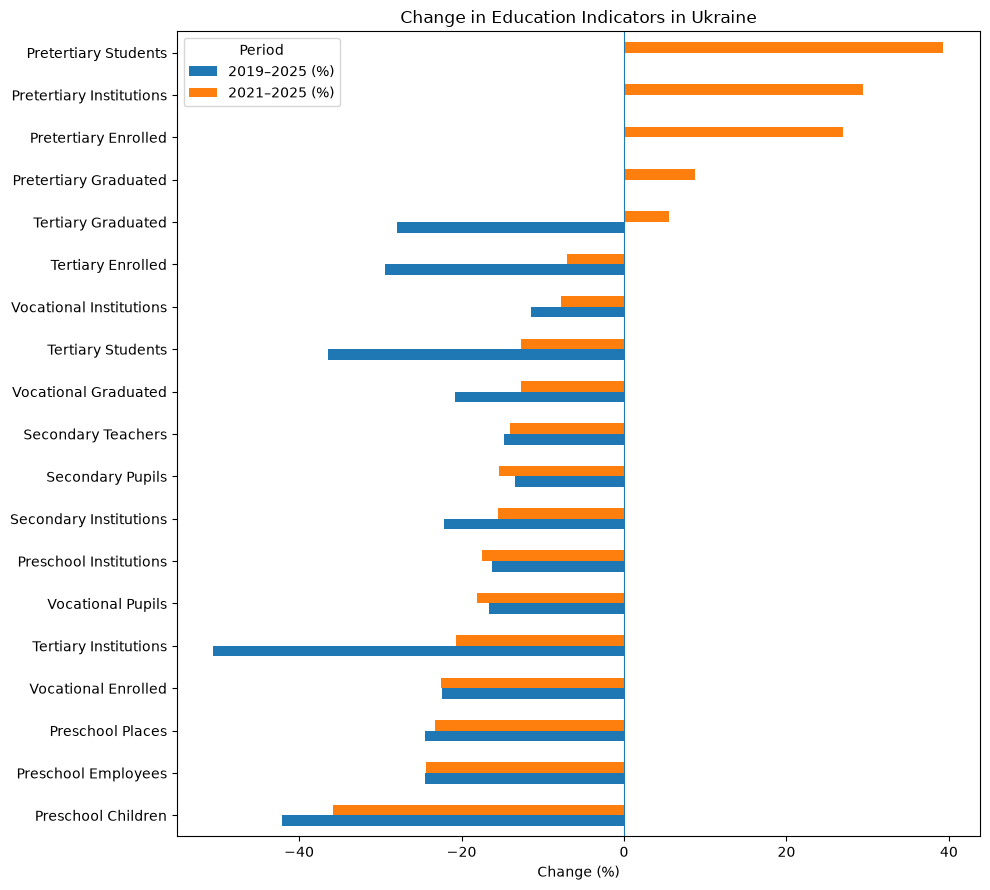

In [33]:
# Use cleaner labels for the figure
plot_data = change_comparison.copy()

plot_data.index = (
    plot_data.index
    .str.replace("_", " ")
    .str.title()
)

ax = plot_data.plot(
    kind="barh",
    figsize=(10, 9)
)

plt.axvline(0, linewidth=0.8)
plt.title("Change in Education Indicators in Ukraine")
plt.xlabel("Change (%)")
plt.ylabel("")
plt.legend(title="Period")
plt.tight_layout()
plt.show()

In [34]:
# Compare the number of secondary pupils by region
# between 2021 and 2025

secondary_by_region = (
    df_education_wide[
        ["Region", "Year", "secondary_pupils"]
    ]
    .pivot(
        index="Region",
        columns="Year",
        values="secondary_pupils"
    )
)

secondary_by_region["change_2021_2025_pct"] = (
    (secondary_by_region[2025] - secondary_by_region[2021])
    / secondary_by_region[2021]
    * 100
)

secondary_change = (
    secondary_by_region["change_2021_2025_pct"]
    .sort_values()
)

secondary_change.round(2)

Region
Luhanska           -69.85
Donetska           -61.95
Khersonska         -55.34
Zaporizka          -40.24
Kharkivska         -25.07
Mykolaivska        -20.14
Sumska             -19.43
Dnipropetrovska    -15.01
Chernihivska       -14.55
Odeska             -13.55
Ternopilska        -11.11
Zhytomyrska        -10.09
Zakarpatska         -9.98
Kirovohradska       -8.81
Volynska            -8.40
Poltavska           -8.40
Vinnytska           -7.49
Khmelnytska         -7.16
Ivano-Frankivska    -6.76
Chernivetska        -6.48
Cherkaska           -6.26
Rivnenska           -5.45
Lvivska             -4.43
Kyivska             -3.87
Kyiv                -2.64
Name: change_2021_2025_pct, dtype: float64

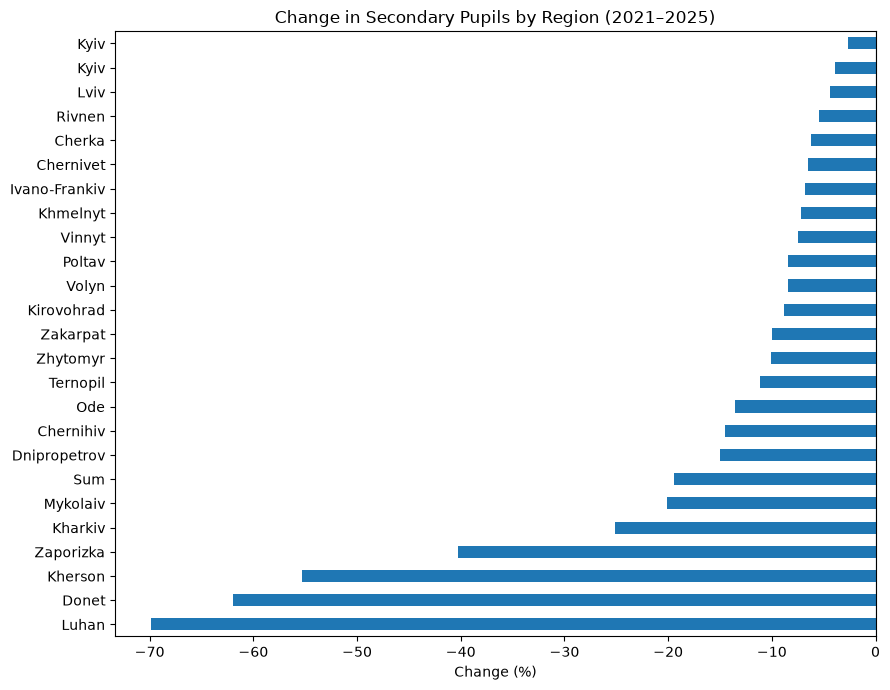

In [35]:
# Plot regional changes in the number of secondary pupils

plot_secondary = secondary_change.copy()

plot_secondary.index = (
    plot_secondary.index
    .str.replace("ska$", "", regex=True)
)

plt.figure(figsize=(9, 7))
plot_secondary.plot(kind="barh")

plt.axvline(0, linewidth=0.8)
plt.title("Change in Secondary Pupils by Region (2021–2025)")
plt.xlabel("Change (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [36]:
# Student-related indicators used to compare education levels

student_indicators = [
    "preschool_children",
    "secondary_pupils",
    "vocational_pupils",
    "pretertiary_students",
    "tertiary_students"
]

regional_student_changes = {}

for indicator in student_indicators:
    
    temp = df_education_wide[
        ["Region", "Year", indicator]
    ].pivot(
        index="Region",
        columns="Year",
        values=indicator
    )

    regional_student_changes[indicator] = (
        (temp[2025] - temp[2021])
        / temp[2021]
        * 100
    )

regional_student_changes = pd.DataFrame(
    regional_student_changes
)

regional_student_changes.round(2)

,preschool_children,secondary_pupils,vocational_pupils,pretertiary_students,tertiary_students
Region,,,,,
Cherkaska,-30.07,-6.26,-21.74,176.79,-14.02
Chernihivska,-34.43,-14.55,14.51,27.48,2.09
Chernivetska,-25.25,-6.48,-13.93,58.13,-5.47
Dnipropetrovska,-34.09,-15.01,-10.05,60.99,-14.02
Donetska,-89.58,-61.95,-62.82,-52.12,NaN
Ivano-Frankivska,-17.72,-6.76,-22.74,96.27,7.69
Kharkivska,-44.02,-25.07,-25.89,129.00,-35.07
Khersonska,-83.20,-55.34,-54.22,NaN,NaN
Khmelnytska,-22.22,-7.16,-0.91,92.17,-9.45


In [37]:
# Summarize regional changes for each education level

regional_change_summary = pd.DataFrame({
    "median_change_pct": regional_student_changes.median(),
    "mean_change_pct": regional_student_changes.mean(),
    "min_change_pct": regional_student_changes.min(),
    "max_change_pct": regional_student_changes.max(),
    "available_regions": regional_student_changes.count()
})

regional_change_summary.round(2)

,median_change_pct,mean_change_pct,min_change_pct,max_change_pct,available_regions
preschool_children,-32.04,-37.58,-98.41,-17.01,25
secondary_pupils,-9.98,-17.70,-69.85,-2.64,25
vocational_pupils,-14.82,-19.54,-79.50,14.51,25
pretertiary_students,48.29,50.48,-52.12,176.79,23
tertiary_students,-1.65,-0.81,-35.07,37.20,22


### Regional differences in student numbers

The changes between 2021 and 2025 are quite different depending on the region and the education level.

Pre-school education has the largest overall decrease, with a median decline of around 32%. Secondary and vocational education also decrease in most regions.

The biggest decreases are mostly seen in Luhanska, Donetska, Khersonska, Zaporizka and Kharkivska.

Pretertiary education behaves differently, with increases in many regions. Tertiary education is more mixed, with both increases and decreases.

Later, we can compare these regional differences with conflict intensity.

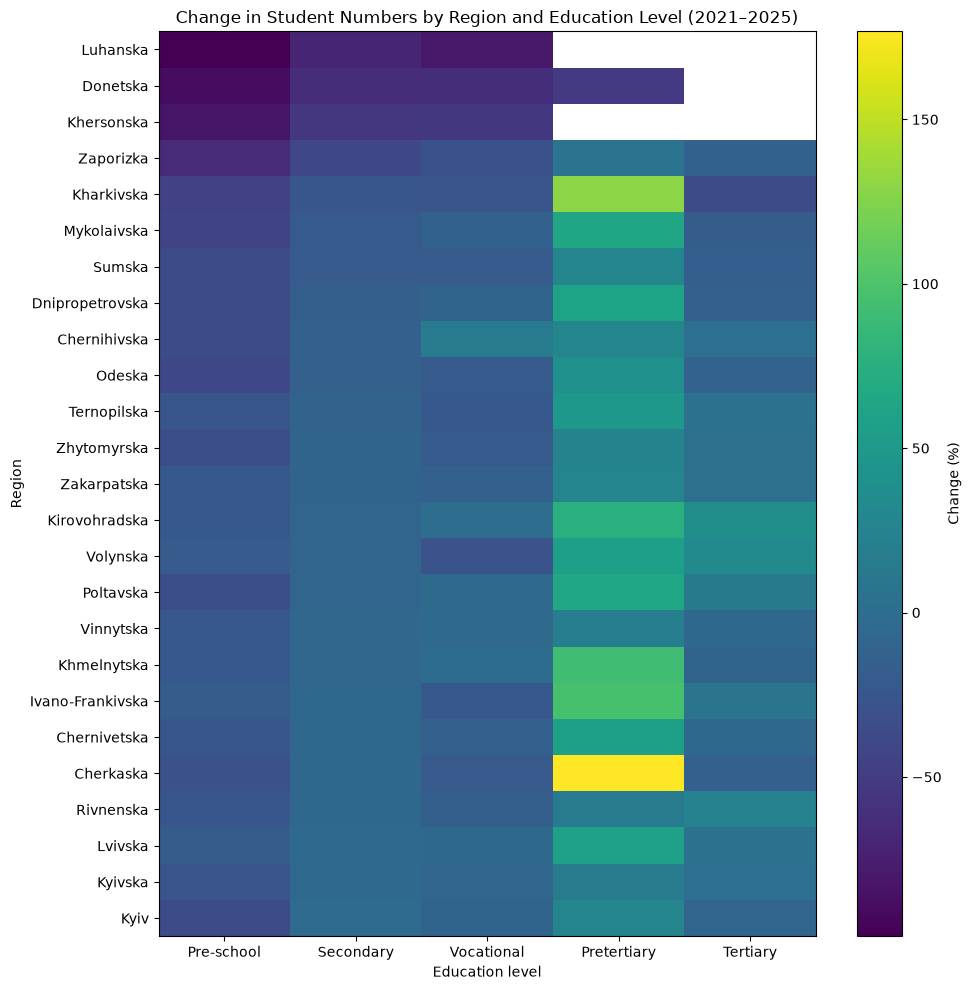

In [38]:
# Prepare regional changes for visualization

heatmap_data = regional_student_changes.copy()

heatmap_data.columns = [
    "Pre-school",
    "Secondary",
    "Vocational",
    "Pretertiary",
    "Tertiary"
]

# Sort regions by the change in secondary pupils
heatmap_data = heatmap_data.sort_values("Secondary")

# Plot the regional percentage changes
fig, ax = plt.subplots(figsize=(10, 10))

im = ax.imshow(
    heatmap_data.values,
    aspect="auto"
)

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

plt.colorbar(im, ax=ax, label="Change (%)")

plt.title("Change in Student Numbers by Region and Education Level (2021–2025)")
plt.xlabel("Education level")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

In [39]:
# Focus on indicators with complete or almost complete regional coverage

main_student_indicators = [
    "preschool_children",
    "secondary_pupils",
    "vocational_pupils"
]

# Show the five largest regional decreases for each indicator

for indicator in main_student_indicators:
    print(f"\n{indicator}")
    print(
        regional_student_changes[indicator]
        .nsmallest(5)
        .round(2)
    )


preschool_children
Region
Luhanska     -98.41
Donetska     -89.58
Khersonska   -83.20
Zaporizka    -65.79
Kharkivska   -44.02
Name: preschool_children, dtype: float64

secondary_pupils
Region
Luhanska     -69.85
Donetska     -61.95
Khersonska   -55.34
Zaporizka    -40.24
Kharkivska   -25.07
Name: secondary_pupils, dtype: float64

vocational_pupils
Region
Luhanska     -79.50
Donetska     -62.82
Khersonska   -54.22
Zaporizka    -28.99
Volynska     -27.47
Name: vocational_pupils, dtype: float64


### Regions with the largest decreases

The same regions appear several times among the largest decreases.

Luhanska, Donetska, Khersonska and Zaporizka have strong decreases in pre-school, secondary and vocational education.

Kharkivska also shows a large decrease in pre-school and secondary education.

Later, we can compare these regions with conflict intensity.

In [40]:
# Count how often each region appears among the five largest decreases

from collections import Counter

top_regions = []

for indicator in main_student_indicators:
    top_regions.extend(
        regional_student_changes[indicator]
        .nsmallest(5)
        .index
    )

top_region_counts = Counter(top_regions)

pd.Series(top_region_counts).sort_values(ascending=False)

Luhanska      3
Donetska      3
Khersonska    3
Zaporizka     3
Kharkivska    2
Volynska      1
dtype: int64

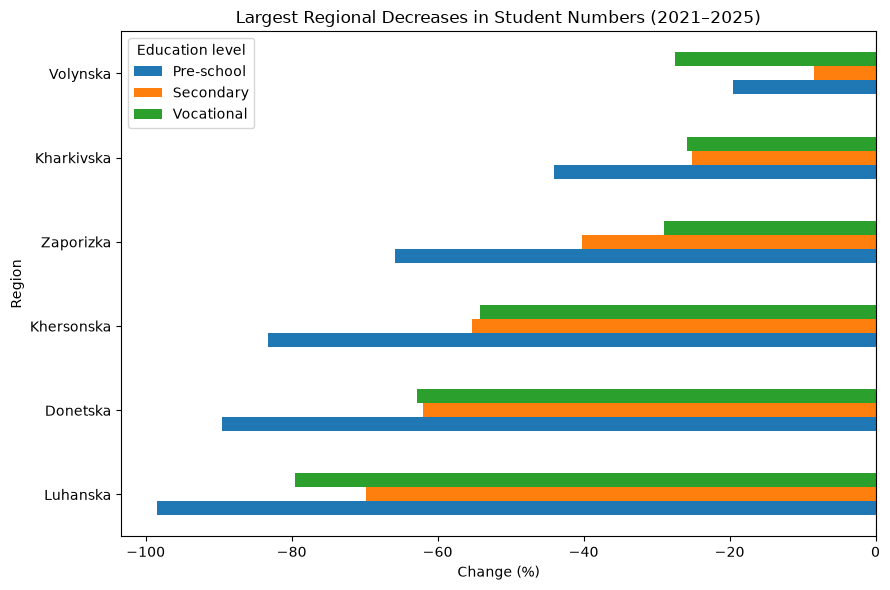

In [41]:
# Select the regions that appear among the largest decreases
regions_to_plot = [
    "Luhanska",
    "Donetska",
    "Khersonska",
    "Zaporizka",
    "Kharkivska",
    "Volynska"
]

# Keep the three indicators with the best regional coverage
top_declines_plot = regional_student_changes.loc[
    regions_to_plot,
    [
        "preschool_children",
        "secondary_pupils",
        "vocational_pupils"
    ]
].copy()

# Use cleaner labels
top_declines_plot.columns = [
    "Pre-school",
    "Secondary",
    "Vocational"
]

# Plot the comparison
top_declines_plot.plot(
    kind="barh",
    figsize=(9, 6)
)

plt.axvline(0, linewidth=0.8)
plt.title("Largest Regional Decreases in Student Numbers (2021–2025)")
plt.xlabel("Change (%)")
plt.ylabel("Region")
plt.legend(title="Education level")
plt.tight_layout()
plt.show()

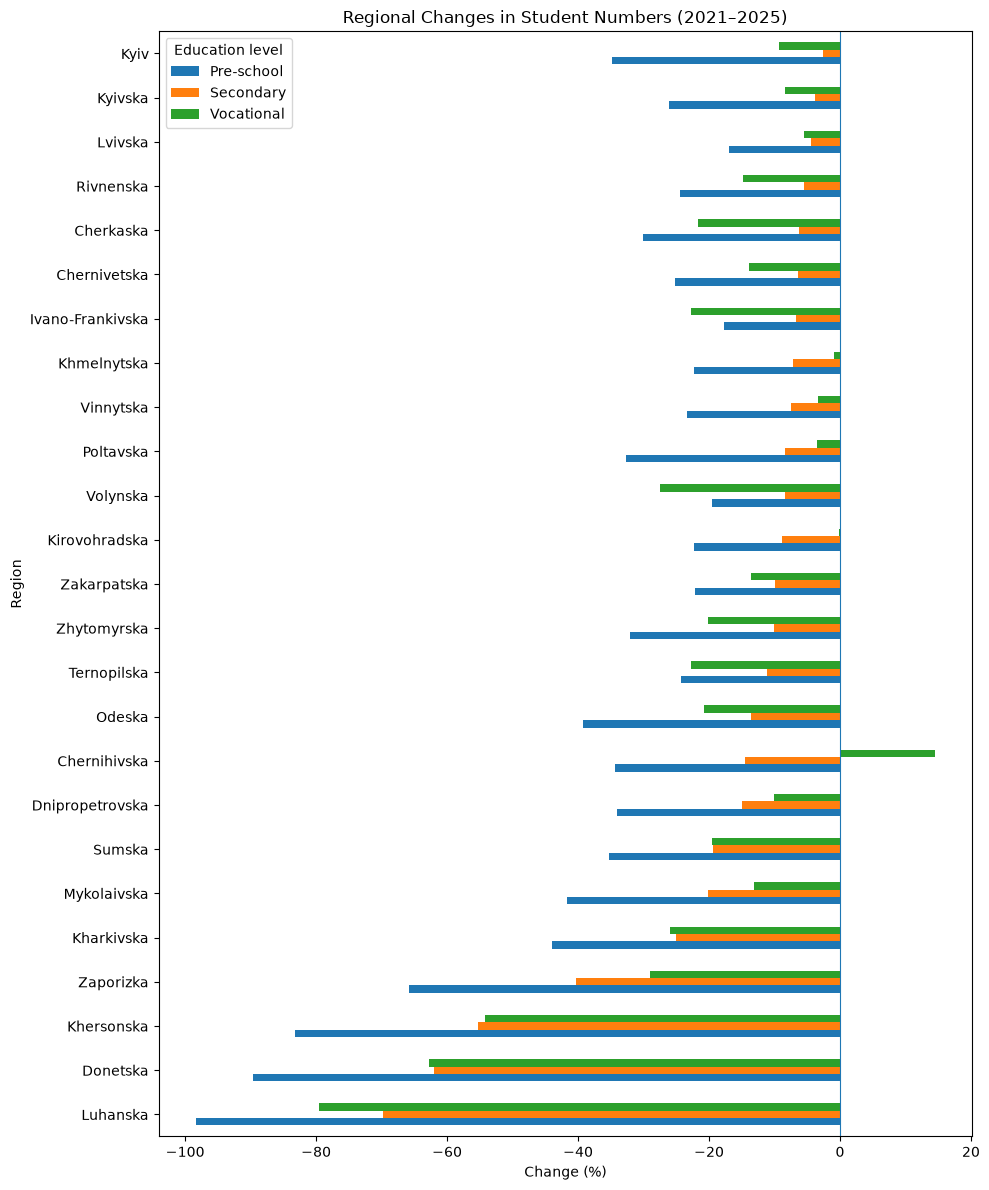

In [43]:
# Plot all regions for the three main student-related indicators

all_regions_plot = regional_student_changes[
    [
        "preschool_children",
        "secondary_pupils",
        "vocational_pupils"
    ]
].copy()

# Use cleaner labels
all_regions_plot.columns = [
    "Pre-school",
    "Secondary",
    "Vocational"
]

# Sort regions by secondary change for readability
all_regions_plot = all_regions_plot.sort_values("Secondary")

# Plot all regions
all_regions_plot.plot(
    kind="barh",
    figsize=(10, 12)
)

plt.axvline(0, linewidth=0.8)
plt.title("Regional Changes in Student Numbers (2021–2025)")
plt.xlabel("Change (%)")
plt.ylabel("Region")
plt.legend(title="Education level")
plt.tight_layout()
plt.show()

In [47]:
# Institution indicators for each education level

institution_indicators = [
    "preschool_institutions",
    "secondary_institutions",
    "vocational_institutions",
    "pretertiary_institutions",
    "tertiary_institutions"
]

institution_changes = {}

for indicator in institution_indicators:
    
    temp = df_education_wide[
        ["Region", "Year", indicator]
    ].pivot(
        index="Region",
        columns="Year",
        values=indicator
    )

    institution_changes[indicator] = (
        (temp[2025] - temp[2021])
        / temp[2021]
        * 100
    )

institution_changes = pd.DataFrame(institution_changes)

institution_changes.describe().round(2)

,preschool_institutions,secondary_institutions,vocational_institutions,pretertiary_institutions,tertiary_institutions
count,25.00,25.00,25.00,23.00,22.00
mean,-20.67,-18.16,-7.71,34.51,-8.66
std,25.76,18.47,10.57,40.94,15.99
min,-92.31,-69.69,-42.11,-30.00,-46.15
25%,-20.70,-20.83,-10.81,0.00,-19.17
50%,-12.71,-13.25,-4.00,28.57,-5.95
75%,-5.67,-7.78,0.00,45.42,0.00
max,2.44,5.35,0.00,128.57,14.29


In [48]:
# Median regional change in the number of institutions

institution_medians = (
    institution_changes
    .median()
    .sort_values()
)

institution_medians.round(2)

secondary_institutions     -13.25
preschool_institutions     -12.71
tertiary_institutions       -5.95
vocational_institutions     -4.00
pretertiary_institutions    28.57
dtype: float64

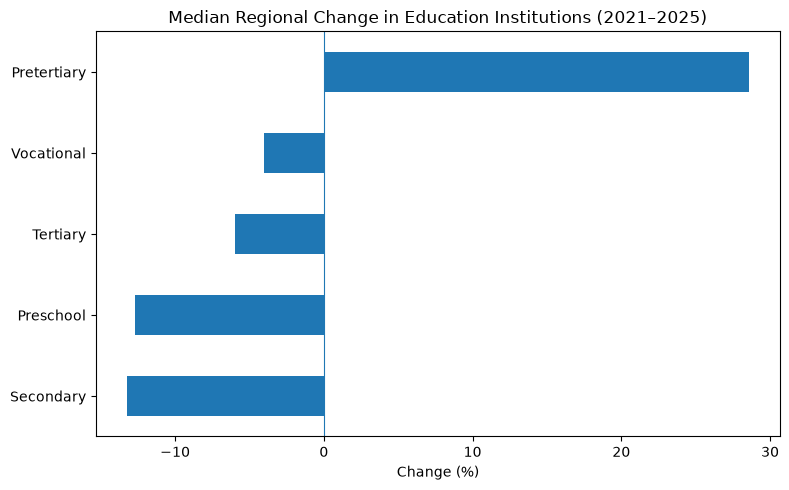

In [49]:
# Plot the median regional change in institutions

plot_institutions = institution_medians.copy()

plot_institutions.index = (
    plot_institutions.index
    .str.replace("_institutions", "", regex=False)
    .str.replace("_", " ")
    .str.title()
)

plt.figure(figsize=(8, 5))
plot_institutions.plot(kind="barh")

plt.axvline(0, linewidth=0.8)
plt.title("Median Regional Change in Education Institutions (2021–2025)")
plt.xlabel("Change (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [50]:
# Compare national student trends using 2021 as a common baseline

student_national = national_wide[
    [
        "preschool_children",
        "secondary_pupils",
        "vocational_pupils",
        "pretertiary_students",
        "tertiary_students"
    ]
].copy()

# Set 2021 = 100 for each indicator
student_index = (
    student_national
    / student_national.loc[2021]
    * 100
)

student_index

Indicator,preschool_children,secondary_pupils,vocational_pupils,pretertiary_students,tertiary_students
Year,,,,,
2019,110.711220,97.827796,98.178049,NaN,137.551222
2020,103.526047,99.554435,98.609469,58.664844,109.097432
2021,100.000000,100.000000,100.000000,100.000000,100.000000
2022,84.073269,95.546902,94.548527,106.887953,100.678438
2023,77.519125,92.336724,89.956698,123.977841,109.744150
2024,70.229305,88.500477,85.642896,135.822952,91.376261
2025,64.154575,84.646311,81.893136,139.333166,87.380729


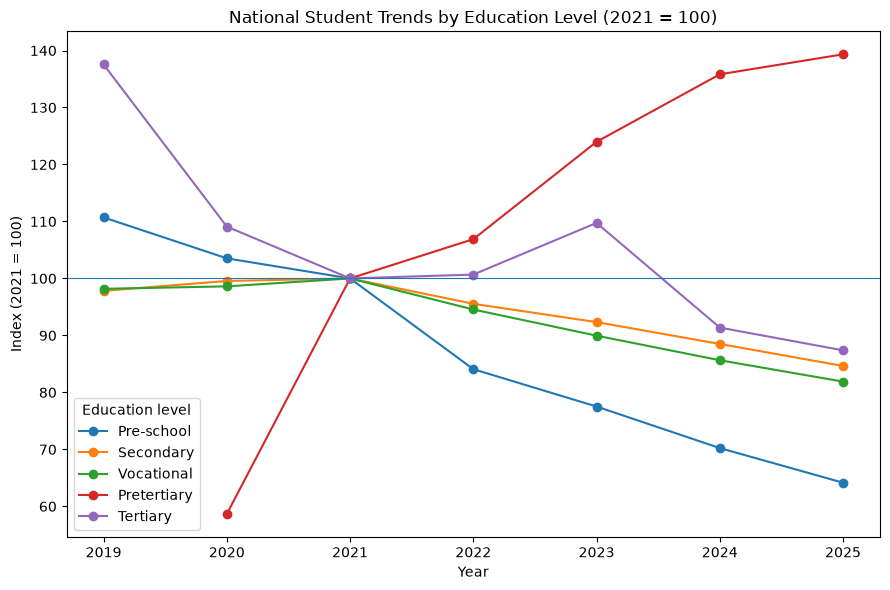

In [51]:
# Plot national trends relative to the 2021 level

plot_index = student_index.copy()

plot_index.columns = [
    "Pre-school",
    "Secondary",
    "Vocational",
    "Pretertiary",
    "Tertiary"
]

plot_index.plot(
    figsize=(9, 6),
    marker="o"
)

plt.axhline(100, linewidth=0.8)
plt.title("National Student Trends by Education Level (2021 = 100)")
plt.xlabel("Year")
plt.ylabel("Index (2021 = 100)")
plt.legend(title="Education level")
plt.tight_layout()
plt.show()

### Note: Pretertiary data are not available for 2019.